In [1]:
!pip install -q transformers datasets accelerate evaluate sentencepiece matplotlib seaborn scikit-learn

import transformers
print(transformers.__version__)

import random, numpy as np, torch, time
from datasets import load_dataset, Value
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer
)
import evaluate
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, precision_recall_curve, auc

5.20.2


In [2]:
# ==================== LOAD SHARED DATA ====================
import pandas as pd
from datasets import Dataset

BASE_URL = "https://raw.githubusercontent.com/OswinJTC/IE4483-AI-Data-Mining-Project/main/data/processed"

train = Dataset.from_pandas(
    pd.read_json(f"{BASE_URL}/train_split.json")
)
val = Dataset.from_pandas(
    pd.read_json(f"{BASE_URL}/val_split.json")
)
test = Dataset.from_pandas(
    pd.read_json(f"{BASE_URL}/test_split.json")
)

print(f"Training: {len(train)}")
print(f"Validation: {len(val)}")
print(f"Test: {len(test)}")

for name, ds in [("Train", train), ("Validation", val)]:
    counts = pd.Series(ds["sentiments"]).value_counts()
    print(f"\n{name} Class Distribution:")
    print(counts)
    print("Positive %:", round((counts.get(1, 0) / len(ds)) * 100, 2))
    print("Negative %:", round((counts.get(0, 0) / len(ds)) * 100, 2))

# ==================== MAJORITY BASELINE ====================
from sklearn.metrics import accuracy_score, f1_score

y_true = np.array(val["sentiments"]).astype(int)
y_pred = np.ones(len(y_true), dtype=int)

print("\n========== MAJORITY BASELINE ==========")
print("Strategy: Always predict Positive")
print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
print(f"Positive F1: {f1_score(y_true, y_pred, pos_label=1):.4f}")
print(f"Negative F1: {f1_score(y_true, y_pred, pos_label=0, zero_division=0):.4f}")
print(f"Macro F1: {f1_score(y_true, y_pred, average='macro'):.4f}")

Training: 6104
Validation: 1078
Test: 1851

Train Class Distribution:
1    5213
0     891
Name: count, dtype: int64
Positive %: 85.4
Negative %: 14.6

Validation Class Distribution:
1    921
0    157
Name: count, dtype: int64
Positive %: 85.44
Negative %: 14.56

========== MAJORITY BASELINE ==========
Strategy: Always predict Positive
Accuracy: 0.8544
Positive F1: 0.9215
Negative F1: 0.0000
Macro F1: 0.4607


In [3]:
# ==================== SETUP ====================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU Only")
assert torch.cuda.is_available(), "GPU not enabled!"

GPU: Tesla T4


In [4]:
# ==================== HELPER FUNCTIONS 1====================
def prepare_dataset(train, val, test, tokenizer):
    """Tokenize and prepare datasets for Sentiment Classification"""
    def preprocess(batch):
        # Tokenize 'reviews' text
        return tokenizer(batch["reviews"], truncation=True, max_length=128)

    def add_labels_train(example):
        example["labels"] = int(example["sentiments"])
        return example

    # Tokenize the datasets
    train_enc = train.map(preprocess, batched=True, remove_columns=["reviews"])
    val_enc = val.map(preprocess, batched=True, remove_columns=["reviews"])
    test_enc = test.map(preprocess, batched=True, remove_columns=["reviews"])

    # Set 'labels'
    train_enc = train_enc.map(add_labels_train, remove_columns=["sentiments"])
    val_enc = val_enc.map(add_labels_train, remove_columns=["sentiments"])

    # Set format to PyTorch tensors
    train_enc.set_format("torch", columns=['input_ids', 'attention_mask', 'labels'])
    val_enc.set_format("torch", columns=['input_ids', 'attention_mask', 'labels'])
    test_enc.set_format("torch", columns=["input_ids", "attention_mask"])

    return train_enc, val_enc, test_enc

In [5]:
# ==================== HELPER FUNCTIONS 2====================
def get_compute_metrics():
    accuracy = evaluate.load("accuracy")
    precision = evaluate.load("precision")
    recall = evaluate.load("recall")
    f1 = evaluate.load("f1")

    def compute_metrics(eval_pred):
        logits, labels = eval_pred
        preds = logits.argmax(-1)
        return {
            "accuracy": accuracy.compute(predictions=preds, references=labels)["accuracy"],
            "precision": precision.compute(predictions=preds, references=labels, average="binary")["precision"],
            "recall": recall.compute(predictions=preds, references=labels, average="binary")["recall"],
            "f1": f1.compute(predictions=preds, references=labels, average="binary")["f1"],
            "negative_f1": f1.compute(predictions=preds, references=labels, average="binary", pos_label=0)["f1"],
            "macro_f1": f1.compute(predictions=preds, references=labels, average="macro")["f1"],
        }
    return compute_metrics

In [6]:

# ==================== ANALYSIS FUNCTION 1 ====================
def plot_training_curves(trainer, model_name):
    logs = trainer.state.log_history

    train_logs = [
        log for log in logs
        if "loss" in log and "epoch" in log
    ]
    eval_logs = [
        log for log in logs
        if "eval_loss" in log and "epoch" in log
    ]

    train_epochs = [log["epoch"] for log in train_logs]
    train_loss = [log["loss"] for log in train_logs]

    eval_epochs = [log["epoch"] for log in eval_logs]
    eval_loss = [log["eval_loss"] for log in eval_logs]
    eval_f1 = [log["eval_negative_f1"] for log in eval_logs]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    # Training and validation loss by actual epoch
    ax1.plot(train_epochs, train_loss, "o-", label="Train Loss")
    ax1.plot(eval_epochs, eval_loss, "s-", label="Validation Loss")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.set_title(f"{model_name} - Loss")
    ax1.set_xlim(0, trainer.args.num_train_epochs)
    ax1.legend()
    ax1.grid(alpha=0.3)

    # Validation F1 by actual epoch
    ax2.plot(eval_epochs, eval_f1, "o-")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Negative F1 Score")
    ax2.set_title(f"{model_name} - Validation Negative F1")
    ax2.set_xlim(0, trainer.args.num_train_epochs)
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(
        f"/content/{model_name}_curves.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()


In [7]:
# ==================== ANALYSIS FUNCTION 2====================
def plot_confusion_matrix(model, tokenizer, test_enc, model_name):
    device = model.device
    all_preds, all_labels = [], []

    for example in test_enc:
        inputs = {k: v.unsqueeze(0).to(device) for k, v in example.items() if k != 'labels'}
        with torch.no_grad():
            logits = model(**inputs).logits
        all_preds.append(logits.argmax(-1).item())
        all_labels.append(example['labels'].item())

    cm = confusion_matrix(all_labels, all_preds)

    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Negative', 'Positive'],
                yticklabels=['Negative', 'Positive'])
    plt.ylabel('True')
    plt.xlabel('Predicted')
    plt.title(f'{model_name} - Confusion Matrix')
    plt.tight_layout()
    plt.savefig(f'/content/{model_name}_cm.png', dpi=300, bbox_inches='tight')
    plt.show()

    tn, fp, fn, tp = cm.ravel()

    print(f"TN (True Negative): {tn}")
    print(f"FP (False Positive): {fp}")
    print(f"FN (False Negative): {fn}")
    print(f"TP (True Positive): {tp}")

    print("\n========== ERROR DISTRIBUTION ==========")
    print(f"Negative → Positive: {fp}")
    print(f"Positive → Negative: {fn}")
    print(f"Negative Error Rate: {fp / (tn + fp):.2%}")
    print(f"Positive Error Rate: {fn / (tp + fn):.2%}")

In [8]:
# ==================== ANALYSIS FUNCTION 3====================
def plot_pr_curve(model, tokenizer, test_enc, model_name):
    device = model.device
    all_probs, all_labels = [], []

    for example in test_enc:
        inputs = {
            k: v.unsqueeze(0).to(device)
            for k, v in example.items() if k != "labels"
        }

        with torch.no_grad():
            logits = model(**inputs).logits

        probs = torch.softmax(logits, dim=-1)[0].cpu().numpy()
        all_probs.append(probs)
        all_labels.append(example["labels"].item())

    all_probs = np.array(all_probs)
    all_labels = np.array(all_labels)

    plt.figure(figsize=(7, 5))

    for label, name in [(1, "Positive"), (0, "Negative")]:
        binary_labels = (all_labels == label).astype(int)
        scores = all_probs[:, label]

        precision, recall, _ = precision_recall_curve(
            binary_labels, scores
        )
        pr_auc = auc(recall, precision)

        plt.plot(
            recall, precision,
            label=f"{name} (AUC={pr_auc:.3f})"
        )

    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"{model_name} - PR Curve")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"/content/{model_name}_pr.png", dpi=300, bbox_inches="tight")
    plt.show()

In [9]:
# ==================== ANALYSIS FUNCTION 4====================
def analyze_errors(model, tokenizer, test_data, model_name, n=5):
    """Simple error analysis"""
    device = model.device
    errors = []

    for i, example in enumerate(test_data):
        if len(errors) >= n * 2:
            break
        # Use 'reviews' and 'sentiments' key instead of text/toxicity
        if 'reviews' not in example or 'sentiments' not in example:
            continue
        text = example['reviews']
        true_label = int(example['sentiments'])

        inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=128)
        inputs = {k: v.to(device) for k, v in inputs.items()}

        with torch.no_grad():
            logits = model(**inputs).logits
        pred_label = logits.argmax(-1).item()

        if pred_label != true_label:
            errors.append({
                'text': text[:80],
                'true': true_label,
                'pred': pred_label
            })

    print(f"\n{model_name} - Error Examples (showing {min(n, len(errors))}):")
    for i, e in enumerate(errors[:n], 1):
        print(f"{i}. '{e['text']}...'")
        print(f"   True: {'positive' if e['true']==1 else 'negative'} | Pred: {'positive' if e['pred']==1 else 'negative'}\n")

In [10]:

# ==================== TRAIN & EVALUATE FUNCTION ====================
import os, json, time, shutil
import numpy as np
import pandas as pd
import torch

from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments, Trainer,
    DataCollatorWithPadding, EarlyStoppingCallback
)
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, classification_report
)

# ==================== SAFE CHECKPOINT LOADING ====================
class SafeBestModelTrainer(Trainer):
    def _load_best_model(self):
        path = self.state.best_model_checkpoint
        if not path:
            raise RuntimeError("Best checkpoint not found")

        restored, info = AutoModelForSequenceClassification.from_pretrained(
            path,
            output_loading_info=True
        )

        if info["missing_keys"] or info["unexpected_keys"] or info["error_msgs"]:
            raise RuntimeError(f"Checkpoint loading failed: {info}")

        self.model.load_state_dict(restored.state_dict(), strict=True)
        del restored

        print(f"Best checkpoint restored successfully: {path}")

def train_and_evaluate(
    checkpoint, model_name, train_enc, val_enc,
    test_enc, test_raw, tokenizer, config
):

    output_dir = f"/content/IE4483_BERT/negative_f1/{model_name}"
    os.makedirs(output_dir, exist_ok=True)

    set_seed(config["seed"])

    model = AutoModelForSequenceClassification.from_pretrained(
        checkpoint,
        num_labels=2,
        hidden_dropout_prob=config["dropout"],
        attention_probs_dropout_prob=config["dropout"],
        classifier_dropout=config["dropout"]
    )
    model.config.problem_type = "single_label_classification"

    # Freeze the first N encoder layers if requested
    frozen = config["frozen_layers"]
    for layer in model.bert.encoder.layer[:frozen]:
        for parameter in layer.parameters():
            parameter.requires_grad = False

    args = TrainingArguments(
        output_dir=output_dir,
        learning_rate=config["lr"],
        num_train_epochs=config["epochs"],
        per_device_train_batch_size=config["batch"],
        per_device_eval_batch_size=32,
        weight_decay=config["weight_decay"],
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="negative_f1",
        greater_is_better=True,
        save_total_limit=1,
        report_to="none",
        logging_steps=50,
        seed=config["seed"],
        data_seed=config["seed"]
    )

    callbacks = []
    if config["early_stopping"]:
        callbacks.append(EarlyStoppingCallback(
            early_stopping_patience=2
        ))

    # Separate optimizer configuration
    optimizers = (None, None)
    if config["optimizer"] == "SGD":
        sgd = torch.optim.SGD(
            [p for p in model.parameters() if p.requires_grad],
            lr=config["lr"],
            momentum=0.9,
            weight_decay=config["weight_decay"]
        )
        optimizers = (sgd, None)

    trainer = SafeBestModelTrainer(
        model=model,
        args=args,
        train_dataset=train_enc,
        eval_dataset=val_enc,
        processing_class=tokenizer,
        data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=get_compute_metrics(),
        callbacks=callbacks,
        optimizers=optimizers
    )

    print(f"\n{'='*55}")
    print(f"TRAINING: {model_name}")
    print(config)
    print(f"{'='*55}")

    start = time.time()
    trainer.train()
    elapsed = (time.time() - start) / 60

    # Save selected model and tokenizer
    best_dir = os.path.join(output_dir, "best_model")
    trainer.save_model(best_dir)
    tokenizer.save_pretrained(best_dir)

    # Compute training and validation metrics
    train_out = trainer.predict(train_enc)
    val_out = trainer.predict(val_enc)
    test_out = trainer.predict(test_enc)

    train_pred = train_out.predictions.argmax(axis=-1)
    val_pred = val_out.predictions.argmax(axis=-1)
    test_pred = test_out.predictions.argmax(axis=-1)

    train_true = np.asarray(train_enc["labels"])
    val_true = np.asarray(val_enc["labels"])

    val_precision, val_recall, val_f1, _ = (
        precision_recall_fscore_support(
            val_true, val_pred,
            average="binary", zero_division=0
        )
    )

    neg_precision, neg_recall, neg_f1, _ = (
        precision_recall_fscore_support(
            val_true, val_pred,
            labels=[0], average="macro",
            zero_division=0
        )
    )

    macro_f1 = (val_f1 + neg_f1) / 2

    metrics = {
        "Model": model_name,
        "LR": config["lr"],
        "Epochs": config["epochs"],
        "Batch": config["batch"],
        "Seed": config["seed"],
        "Optimizer": config["optimizer"],
        "Dropout": config["dropout"],
        "Weight Decay": config["weight_decay"],
        "Early Stopping": config["early_stopping"],
        "Frozen Layers": config["frozen_layers"],
        "Train Accuracy": accuracy_score(train_true, train_pred),
        "Validation Accuracy": accuracy_score(val_true, val_pred),
        "Precision": val_precision,
        "Recall": val_recall,
        "F1": val_f1,
        "Negative F1": neg_f1,
        "Macro F1": macro_f1,
        "Negative Recall": neg_recall,
        "Best Epoch": trainer.state.best_model_checkpoint,
        "Time (min)": round(elapsed, 2)
    }

    # Save metrics and configuration
    with open(f"{output_dir}/metrics.json", "w") as f:
        json.dump(metrics, f, indent=2, default=str)

    with open(f"{output_dir}/config.json", "w") as f:
        json.dump(config, f, indent=2)

    pd.DataFrame(trainer.state.log_history).to_csv(
        f"{output_dir}/training_history.csv", index=False
    )

    # Save test predictions
    submission = pd.DataFrame({
        "reviews": list(test_raw["reviews"]),
        "predictions": test_pred.astype(int)
    })
    submission.to_csv(
        f"{output_dir}/submission.csv", index=False
    )

    # Save validation examples for error analysis
    val_df = pd.DataFrame({
        "reviews": list(val["reviews"]),
        "true_label": val_true,
        "prediction": val_pred
    })
    val_df["correct"] = (
        val_df["true_label"] == val_df["prediction"]
    )
    val_df.to_csv(
        f"{output_dir}/validation_predictions.csv",
        index=False
    )

    # Reuse existing analysis functions
    plot_training_curves(trainer, model_name)
    plot_confusion_matrix(
        trainer.model, tokenizer, val_enc, model_name
    )
    plot_pr_curve(
        trainer.model, tokenizer, val_enc, model_name
    )

    # Copy figures from Colab to Google Drive
    figures_dir = f"{output_dir}/figures"
    os.makedirs(figures_dir, exist_ok=True)

    for suffix in ["curves", "cm", "pr"]:
        filename = f"{model_name}_{suffix}.png"
        source = f"/content/{filename}"
        if os.path.exists(source):
            shutil.copy2(source, f"{figures_dir}/{filename}")

    print(f"\nCOMPLETED: {model_name}")
    print(f"Validation F1: {val_f1:.4f}")
    print(f"Negative F1: {neg_f1:.4f}")
    print(f"Saved to: {output_dir}")

    return metrics


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/6104 [00:00<?, ? examples/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Best checkpoint restored successfully: /content/IE4483_BERT/negative_f1/Run_01_Epoch_3/checkpoint-1146


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

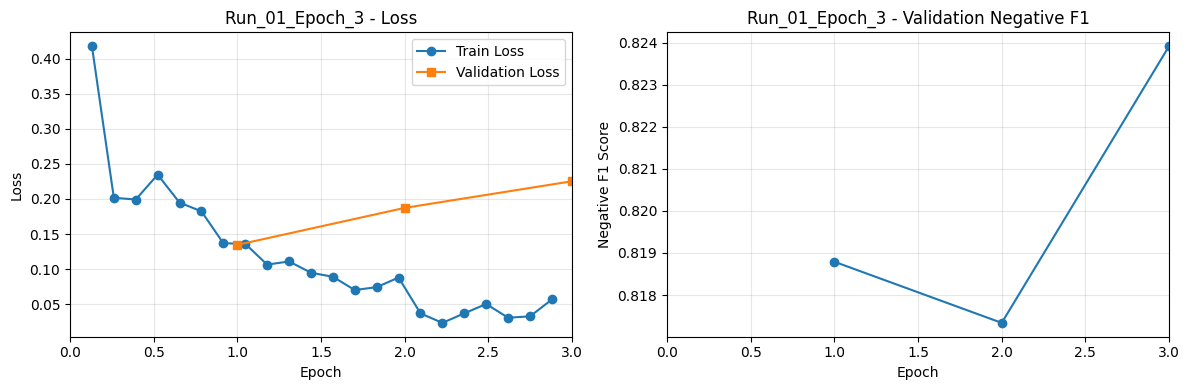

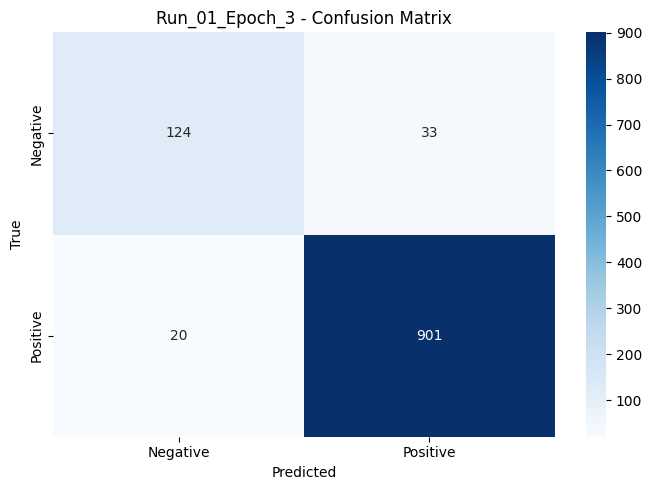

TN (True Negative): 124
FP (False Positive): 33
FN (False Negative): 20
TP (True Positive): 901

========== ERROR DISTRIBUTION ==========
Negative → Positive: 33
Positive → Negative: 20
Negative Error Rate: 21.02%
Positive Error Rate: 2.17%


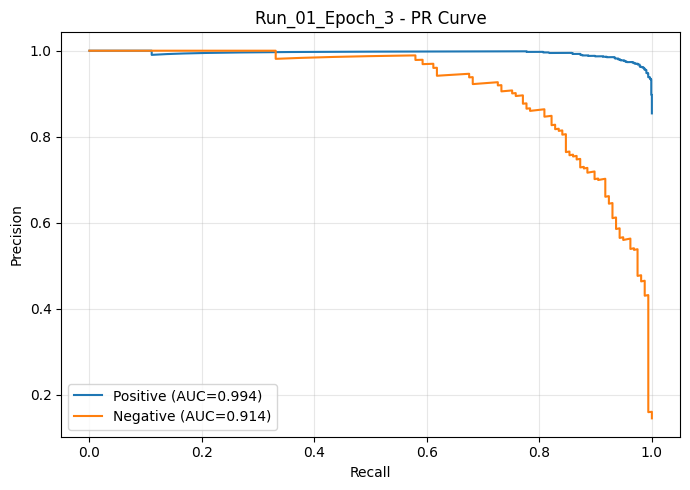


COMPLETED: Run_01_Epoch_3
Validation F1: 0.9714
Negative F1: 0.8239
Saved to: /content/IE4483_BERT/negative_f1/Run_01_Epoch_3


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



TRAINING: Run_02_Epoch_4
{'lr': 3e-05, 'epochs': 4, 'batch': 16, 'seed': 42, 'optimizer': 'AdamW', 'dropout': 0.1, 'weight_decay': 0.01, 'early_stopping': False, 'frozen_layers': 0}


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Negative F1,Macro F1
1,0.149826,0.146547,0.943414,0.976718,0.956569,0.966539,0.816817,0.891678
2,0.088222,0.174448,0.952690,0.973856,0.970684,0.972268,0.839117,0.905692
3,0.051501,0.229344,0.952690,0.958861,0.986971,0.972713,0.822300,0.897506
4,0.000817,0.234304,0.954545,0.965812,0.981542,0.973613,0.836120,0.904867


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Best checkpoint restored successfully: /content/IE4483_BERT/negative_f1/Run_02_Epoch_4/checkpoint-764


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

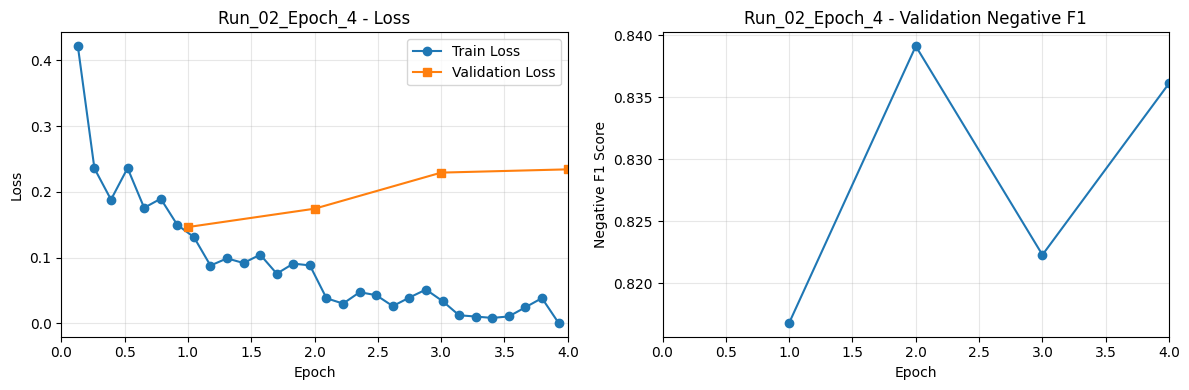

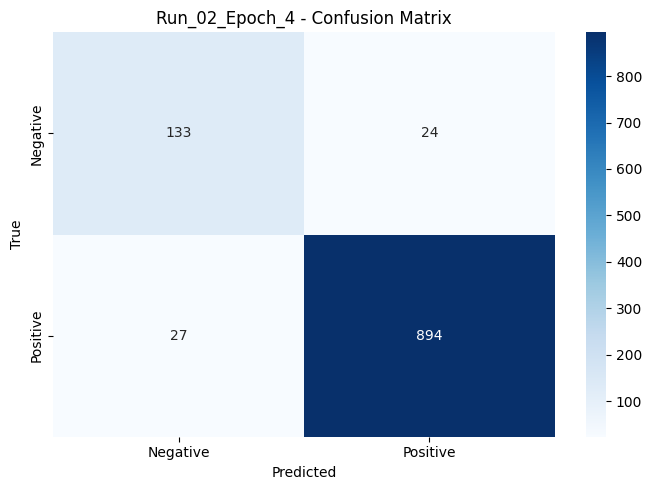

TN (True Negative): 133
FP (False Positive): 24
FN (False Negative): 27
TP (True Positive): 894

========== ERROR DISTRIBUTION ==========
Negative → Positive: 24
Positive → Negative: 27
Negative Error Rate: 15.29%
Positive Error Rate: 2.93%


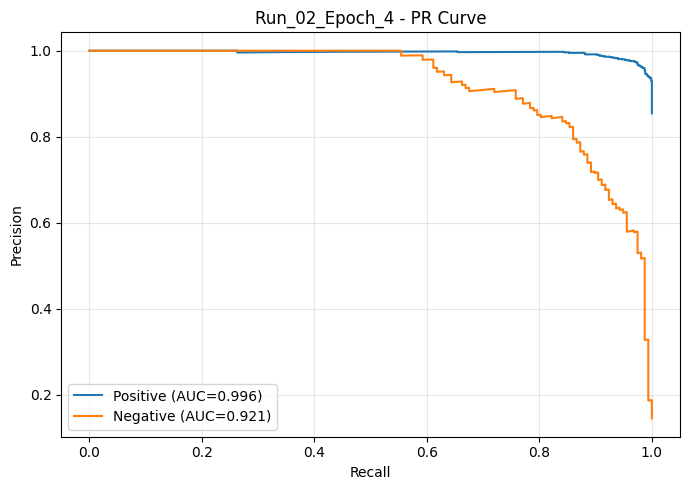


COMPLETED: Run_02_Epoch_4
Validation F1: 0.9723
Negative F1: 0.8391
Saved to: /content/IE4483_BERT/negative_f1/Run_02_Epoch_4


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



TRAINING: Run_03_Epoch_5
{'lr': 3e-05, 'epochs': 5, 'batch': 16, 'seed': 42, 'optimizer': 'AdamW', 'dropout': 0.1, 'weight_decay': 0.01, 'early_stopping': False, 'frozen_layers': 0}


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Negative F1,Macro F1
1,0.160103,0.133257,0.948052,0.974753,0.964169,0.969432,0.827160,0.898296
2,0.093772,0.179373,0.946197,0.964478,0.972856,0.968649,0.810458,0.889553
3,0.056499,0.222669,0.949907,0.972737,0.968512,0.970620,0.830189,0.900404
4,0.001627,0.247751,0.954545,0.968817,0.978284,0.973528,0.839344,0.906436
5,0.013040,0.256792,0.954545,0.965812,0.981542,0.973613,0.836120,0.904867


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Best checkpoint restored successfully: /content/IE4483_BERT/negative_f1/Run_03_Epoch_5/checkpoint-1528


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

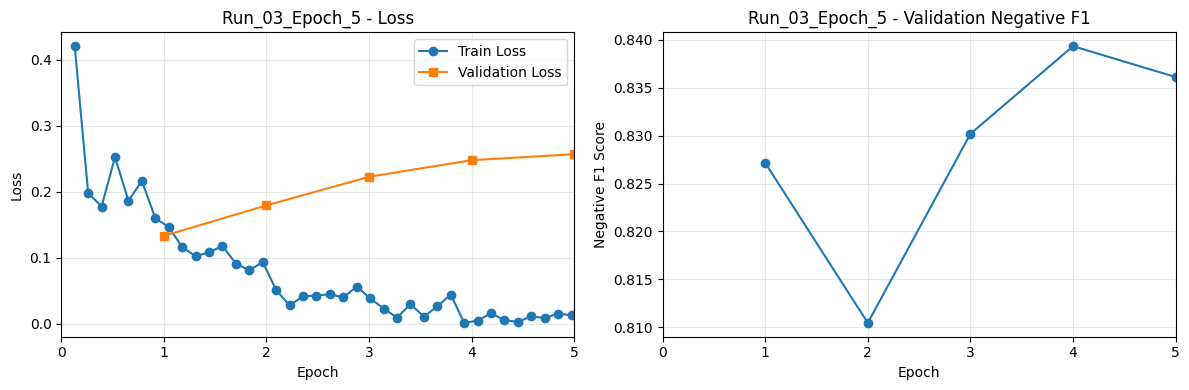

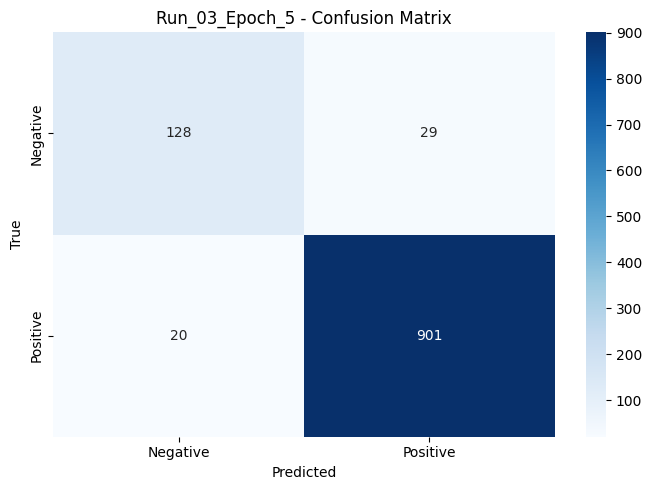

TN (True Negative): 128
FP (False Positive): 29
FN (False Negative): 20
TP (True Positive): 901

========== ERROR DISTRIBUTION ==========
Negative → Positive: 29
Positive → Negative: 20
Negative Error Rate: 18.47%
Positive Error Rate: 2.17%


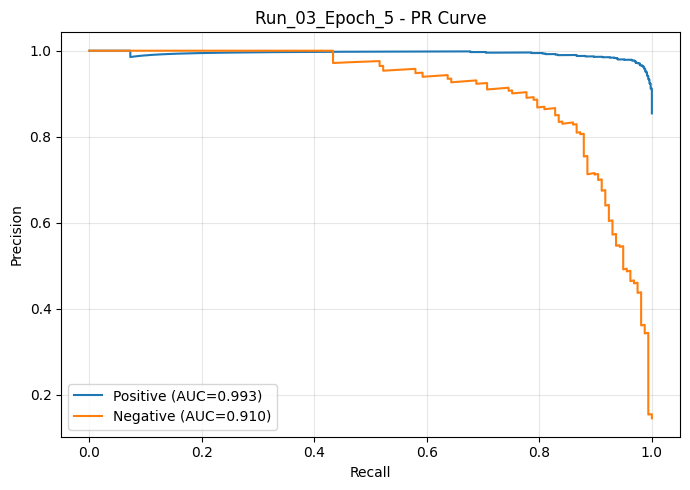


COMPLETED: Run_03_Epoch_5
Validation F1: 0.9735
Negative F1: 0.8393
Saved to: /content/IE4483_BERT/negative_f1/Run_03_Epoch_5


,Model,Epochs,Validation Accuracy,F1,Negative F1,Macro F1,Time (min)
0,Run_01_Epoch_3,3,0.950835,0.971429,0.823920,0.897674,7.46
1,Run_02_Epoch_4,4,0.952690,0.972268,0.839117,0.905692,10.04
2,Run_03_Epoch_5,5,0.954545,0.973528,0.839344,0.906436,12.47



========== STAGE 1 COMPLETED ==========
Best Run: Run_03_Epoch_5
Best Epoch Setting: 5
Validation Positive F1: 0.9735
Validation Negative F1: 0.8393
Macro F1: 0.9064
Saved: /content/IE4483_BERT/negative_f1/stage1_comparison.csv


In [11]:

# ==================== MULTIPLE EXPERIMENTS ====================
import os, gc, json
import pandas as pd
import torch

checkpoint = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

train_enc, val_enc, test_enc = prepare_dataset(
    train, val, test, tokenizer
)

base_dir = "/content/IE4483_BERT/negative_f1"
os.makedirs(base_dir, exist_ok=True)

# ==================== BASELINE CONFIG ====================
baseline = {
    "lr": 3e-5,
    "epochs": 3,
    "batch": 16,
    "seed": 42,
    "optimizer": "AdamW",
    "dropout": 0.1,
    "weight_decay": 0.01,
    "early_stopping": False,
    "frozen_layers": 0
}
# ==================== STAGE 1: EPOCH TUNING ====================
# ACTIVE — Run 01–03

experiments = [
    ("Run_01_Epoch_3", {"epochs": 3}),
    ("Run_02_Epoch_4", {"epochs": 4}),
    ("Run_03_Epoch_5", {"epochs": 5}),
]

# ==================== STAGE 2: LEARNING RATE ====================
# INACTIVE — Run 04–05

# ==================== STAGE 3: BATCH SIZE ====================
# INACTIVE — Run 06

# ==================== STAGE 4: DROPOUT ====================
# TODO: Use best previous configuration
#
# Run 07: dropout = 0.3

# ==================== STAGE 5: WEIGHT DECAY ====================
# TODO: Use best previous configuration
#
# Run 08: weight_decay = 0.05

# ==================== STAGE 6: TRAINING STRATEGY ====================
# TODO: Use best previous configuration
#
# Run 09: frozen_layers = 6
# Run 10: early_stopping = True, epochs = 8

# ==================== STAGE 7: STABILITY ====================
# TODO: Use final best configuration
#
# Run 11: seed = 123

# ==================== EXECUTE CURRENT STAGE ====================
comparison_path = f"{base_dir}/stage1_comparison.csv"

for name, changes in experiments:
    config = {**baseline, **changes}
    run_dir = f"{base_dir}/{name}"

    metrics_path = f"{run_dir}/metrics.json"
    model_path = f"{run_dir}/best_model/model.safetensors"
    submission_path = f"{run_dir}/submission.csv"

    if (
        os.path.exists(metrics_path)
        and os.path.exists(model_path)
        and os.path.exists(submission_path)
    ):
        print(f"SKIPPING COMPLETED: {name}")
        continue

    train_and_evaluate(
        checkpoint, name,
        train_enc, val_enc, test_enc,
        test, tokenizer, config
    )

    gc.collect()
    torch.cuda.empty_cache()

# ==================== STAGE 1 RESULTS ====================
records = []

for name in [
    "Run_01_Epoch_3",
    "Run_02_Epoch_4",
    "Run_03_Epoch_5"
]:
    metrics_path = f"{base_dir}/{name}/metrics.json"

    with open(metrics_path) as f:
        records.append(json.load(f))

df = pd.DataFrame(records)
df.to_csv(comparison_path, index=False)

display(df[[
    "Model",
    "Epochs",
    "Validation Accuracy",
    "F1",
    "Negative F1",
    "Macro F1",
    "Time (min)"
]])

best = df.sort_values(
    ["Negative F1", "F1"],
    ascending=False
).iloc[0]

BEST_EPOCH = int(best["Epochs"])

print("\n========== STAGE 1 COMPLETED ==========")
print("Best Run:", best["Model"])
print("Best Epoch Setting:", BEST_EPOCH)
print("Validation Positive F1:", round(best["F1"], 4))
print("Validation Negative F1:", round(best["Negative F1"], 4))
print("Macro F1:", round(best["Macro F1"], 4))
print("Saved:", comparison_path)

# ==================== NEXT STAGE PLACEHOLDERS ====================
# Stage 2: BEST_EPOCH -> tune Learning Rate
# Stage 3: BEST_EPOCH + BEST_LR -> tune Batch Size
# Stage 4: Tune Dropout
# Stage 5: Tune Weight Decay
# Stage 6: Tune Frozen Layers / Early Stopping
# Stage 7: Validate stability using Seed = 123


In [12]:
# ==================== DOWNLOAD CURRENT STAGE ====================
import shutil
from google.colab import files

base_dir = "/content/IE4483_BERT/negative_f1"

zip_path = shutil.make_archive(
    "/content/BERT_Stage1_Backup",
    "zip",
    base_dir
)

print("Backup created:", zip_path)
files.download(zip_path)

Backup created: /content/BERT_Stage1_Backup.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>